# Quantum Sudoku Solver
**Group 7 · Quantum Computing** — a 4×4 Sudoku solved two ways: classical backtracking and Grover's search on Qiskit Aer.

This notebook is the *workbench*: we try each idea step by step. The finished app (`streamlit run app.py`) has three pages — **Play**, **Solve and Compare**, **Circuit Viewer** — and uses the same `qsudoku` package you see here.

**Contents**
1. The puzzle and the three levels
2. Classical solver: backtracking
3. Why 9×9 is out of reach
4. Encoding a puzzle into qubits
5. Building the oracle, piece by piece
6. The diffuser and the full Grover circuit
7. Running it on Qiskit Aer
8. Checking the circuit against the maths
9. How many rounds? Success probability and over-rotation
10. Medium and Hard
11. Cost of the real circuit
12. Classical vs Grover: the honest comparison
13. What noise does to it
14. Summary

In [1]:
import sys, time
sys.path.insert(0, "..")            # use the qsudoku package next to this folder

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from qsudoku import puzzle as pz, viz
from qsudoku.classical import solve, propagate
from qsudoku.quantum import (SearchProblem, build_oracle, build_diffuser, build_grover_circuit,
                             run_grover, optimal_iterations, theoretical_success, simulate_fast,
                             statevector_probabilities, circuit_stats, AER_QUBIT_LIMIT)
from qsudoku.compare import compare, benchmark

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.precision", 3)
print("ready")

ready


## 1. The puzzle and the three levels
Fill the empty cells so every **row**, **column** and **2×2 box** holds 1, 2, 3, 4 exactly once.
We use three levels, set by the number of blanks: **Easy 4, Medium 6, Hard 8**. Every preset (and every generated puzzle) has exactly one solution.

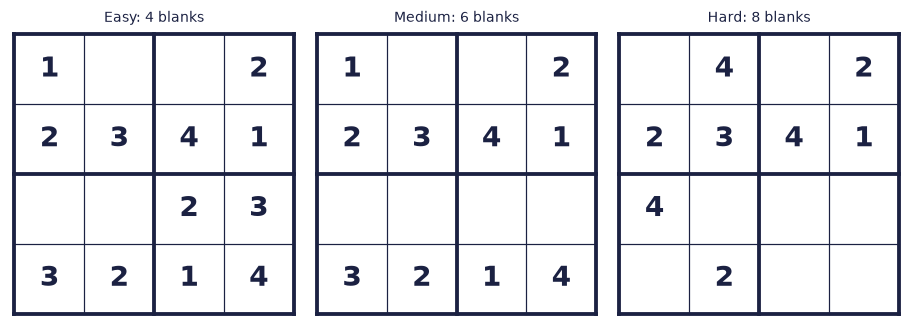

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(8.4, 3))
for ax, level in zip(axes, pz.LEVELS):
    q = pz.PRESETS[level][0]
    viz.draw_grid(q.grid, title=f"{level}: {q.n_blanks} blanks", ax=ax)
plt.tight_layout(); plt.show()

## 2. Classical solver: backtracking
1. Find an empty cell. 2. Try 1 to 4. 3. Check row, column and box. 4. Fine? Go on. 5. Stuck? Go back and try the next number.

We count every candidate digit we test (a *try*), including the ones that clash. That is the classical "effort".

solved=True  tries=8  backtracks=0


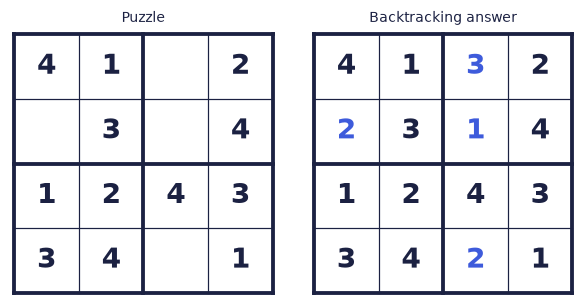

,"(row, col)",digit,event
0,"(0, 2)",1,try
1,"(0, 2)",1,clash
2,"(0, 2)",2,try
3,"(0, 2)",2,clash
4,"(0, 2)",3,try
5,"(0, 2)",3,place
6,"(1, 0)",1,try
7,"(1, 0)",1,clash
8,"(1, 0)",2,try
9,"(1, 0)",2,place


In [3]:
q = pz.PRESETS["Easy"][2]
res = solve(q.grid, record_trace=True)
print(f"solved={res.solved}  tries={res.tries}  backtracks={res.backtracks}")
fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.8))
viz.draw_grid(q.grid, title="Puzzle", ax=axes[0])
viz.draw_grid(res.solution, q.grid, title="Backtracking answer", ax=axes[1])
plt.tight_layout(); plt.show()

steps = [(pz.rc(s.cell), s.value, s.kind) for s in res.trace]
pd.DataFrame(steps, columns=["(row, col)", "digit", "event"]).head(14)

**Pruning.** Before searching, the rules alone can decide many cells (a cell with one candidate, or a digit with one place left in a row/column/box). On a 4×4 grid this often finishes the whole puzzle, which is why the *quantum* part works on the blanks **without** pruning by default — otherwise there would be nothing left to search.

In [4]:
rows = []
for level in pz.LEVELS:
    for q in pz.PRESETS[level]:
        plain, pruned = solve(q.grid), solve(q.grid, pruning=True)
        rows.append({"puzzle": q.name, "blanks": q.n_blanks, "plain tries": plain.tries,
                     "cells decided by rules": pruned.pruned_cells, "tries after pruning": pruned.tries})
pd.DataFrame(rows)

,puzzle,blanks,plain tries,cells decided by rules,tries after pruning
0,Easy 1,4,12,4,0
1,Easy 2,4,11,4,0
2,Easy 3,4,8,4,0
3,Medium 1,6,17,6,0
4,Medium 2,6,17,6,0
5,Medium 3,6,13,6,0
6,Hard 1,8,18,8,0
7,Hard 2,8,20,8,0
8,Hard 3,8,21,8,0


## 3. Why 9×9 is out of reach
Each blank needs enough qubits to hold a digit. A laptop state-vector simulator holds about 30 qubits (2³⁰ amplitudes ≈ 16 GB).

In [5]:
table = pd.DataFrame([
    {"puzzle": "9×9 (51 blanks)", "qubits per blank": 4, "search qubits": 51 * 4},
    {"puzzle": "4×4 Easy (4 blanks)", "qubits per blank": 2, "search qubits": 4 * 2},
    {"puzzle": "4×4 Medium (6 blanks)", "qubits per blank": 2, "search qubits": 6 * 2},
    {"puzzle": "4×4 Hard (8 blanks)", "qubits per blank": 2, "search qubits": 8 * 2},
])
table

,puzzle,qubits per blank,search qubits
0,9×9 (51 blanks),4,204
1,4×4 Easy (4 blanks),2,8
2,4×4 Medium (6 blanks),2,12
3,4×4 Hard (8 blanks),2,16


## 4. Encoding a puzzle into qubits
A blank holds a digit 1–4, so **2 qubits per blank**: `1→00, 2→01, 3→10, 4→11`.
Blank *i* uses qubits `2i` (low bit) and `2i+1` (high bit). A superposition over all search qubits holds *every possible filling at once*.

Besides the search qubits, the oracle needs **helper (flag) qubits**: one per rule.
- *pair rule* — two blanks that see each other must differ
- *clue rule* — a blank must not equal a clue that sees it

In [6]:
rows = []
for level in pz.LEVELS:
    q = pz.PRESETS[level][0]
    sp = SearchProblem.from_grid(q.grid)
    rows.append({"level": level, "blanks": sp.n_blanks, "search qubits": sp.n_search,
                 "pair rules": len(sp.pairs), "clue rules": len(sp.clue_rules),
                 "total qubits": sp.n_qubits, "fillings (4^blanks)": sp.space,
                 "solutions": sp.n_solutions, "Grover rounds": optimal_iterations(sp.space, sp.n_solutions)})
pd.DataFrame(rows)

,level,blanks,search qubits,pair rules,clue rules,total qubits,fillings (4^blanks),solutions,Grover rounds
0,Easy,4,8,3,4,15,256,1,12
1,Medium,6,12,9,6,27,4096,1,50
2,Hard,8,16,15,8,39,65536,1,201


The rounds column is `round(π/(4θ) − ½)` with `sin θ = √(M/N)`; for one solution that is about `π/4·√N`: **12, 50, 201**, matching the proposal.

## 5. Building the oracle, piece by piece
**5a. The "must differ" check for two cells.** Cells *a* and *b* are equal exactly when both bit pairs are equal.
`CX` turns "bits equal" into "target bit is 0"; flipping with `X` and applying a Toffoli (`MCX`) raises a flag when *both* are zero, i.e. when the cells are equal.

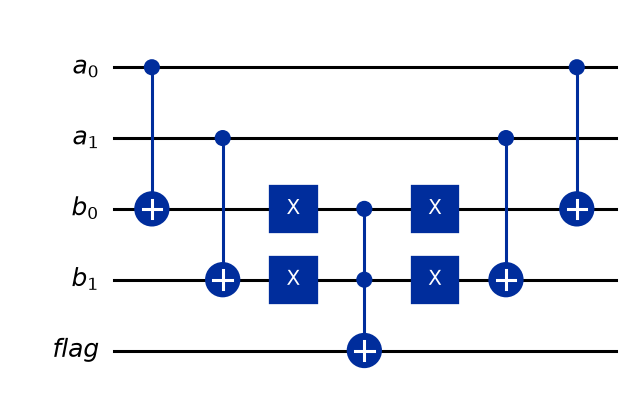

In [7]:
from qiskit import QuantumCircuit, QuantumRegister
a, b, flag = QuantumRegister(2, "a"), QuantumRegister(2, "b"), QuantumRegister(1, "flag")
demo = QuantumCircuit(a, b, flag)
demo.cx(a[0], b[0]); demo.cx(a[1], b[1])          # b <- a xor b
demo.x(b); demo.mcx(list(b), flag[0]); demo.x(b)   # flag = 1  <=>  a == b
demo.cx(a[1], b[1]); demo.cx(a[0], b[0])          # undo
demo.draw("mpl", style={"backgroundcolor": "#FFFFFF"})

**5b. The rules of one puzzle as a graph.** Each edge becomes one flag in the oracle.

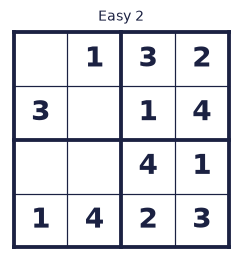

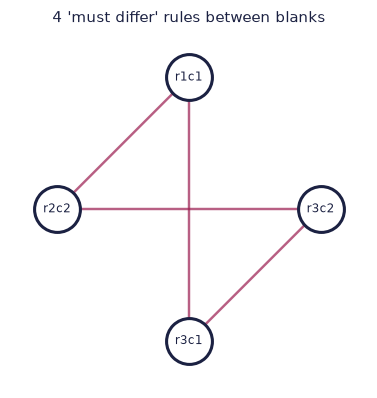

blanks: [(0, 0), (1, 1), (2, 0), (2, 1)] (row, col)
clue rules (forbidden digits per blank): [[1, 2, 3], [1, 3, 4], [1, 3, 4], [1, 4]]


In [8]:
q = pz.PRESETS["Easy"][1]
sp = SearchProblem.from_grid(q.grid)
viz.draw_grid(q.grid, title=f"{q.name}"); plt.show()
viz.plot_constraint_graph(sp); plt.show()
print("blanks:", [pz.rc(c) for c in sp.blanks], "(row, col)")
print("clue rules (forbidden digits per blank):", [sorted(f) for f in sp.forbidden])

**5c. The whole oracle.** Compute every rule into its flag → flip the sign if **no** flag is up (`X` on flags, then a multi-controlled `Z`) → undo the checks so the flags return to 0.

16 qubits, 161 operations


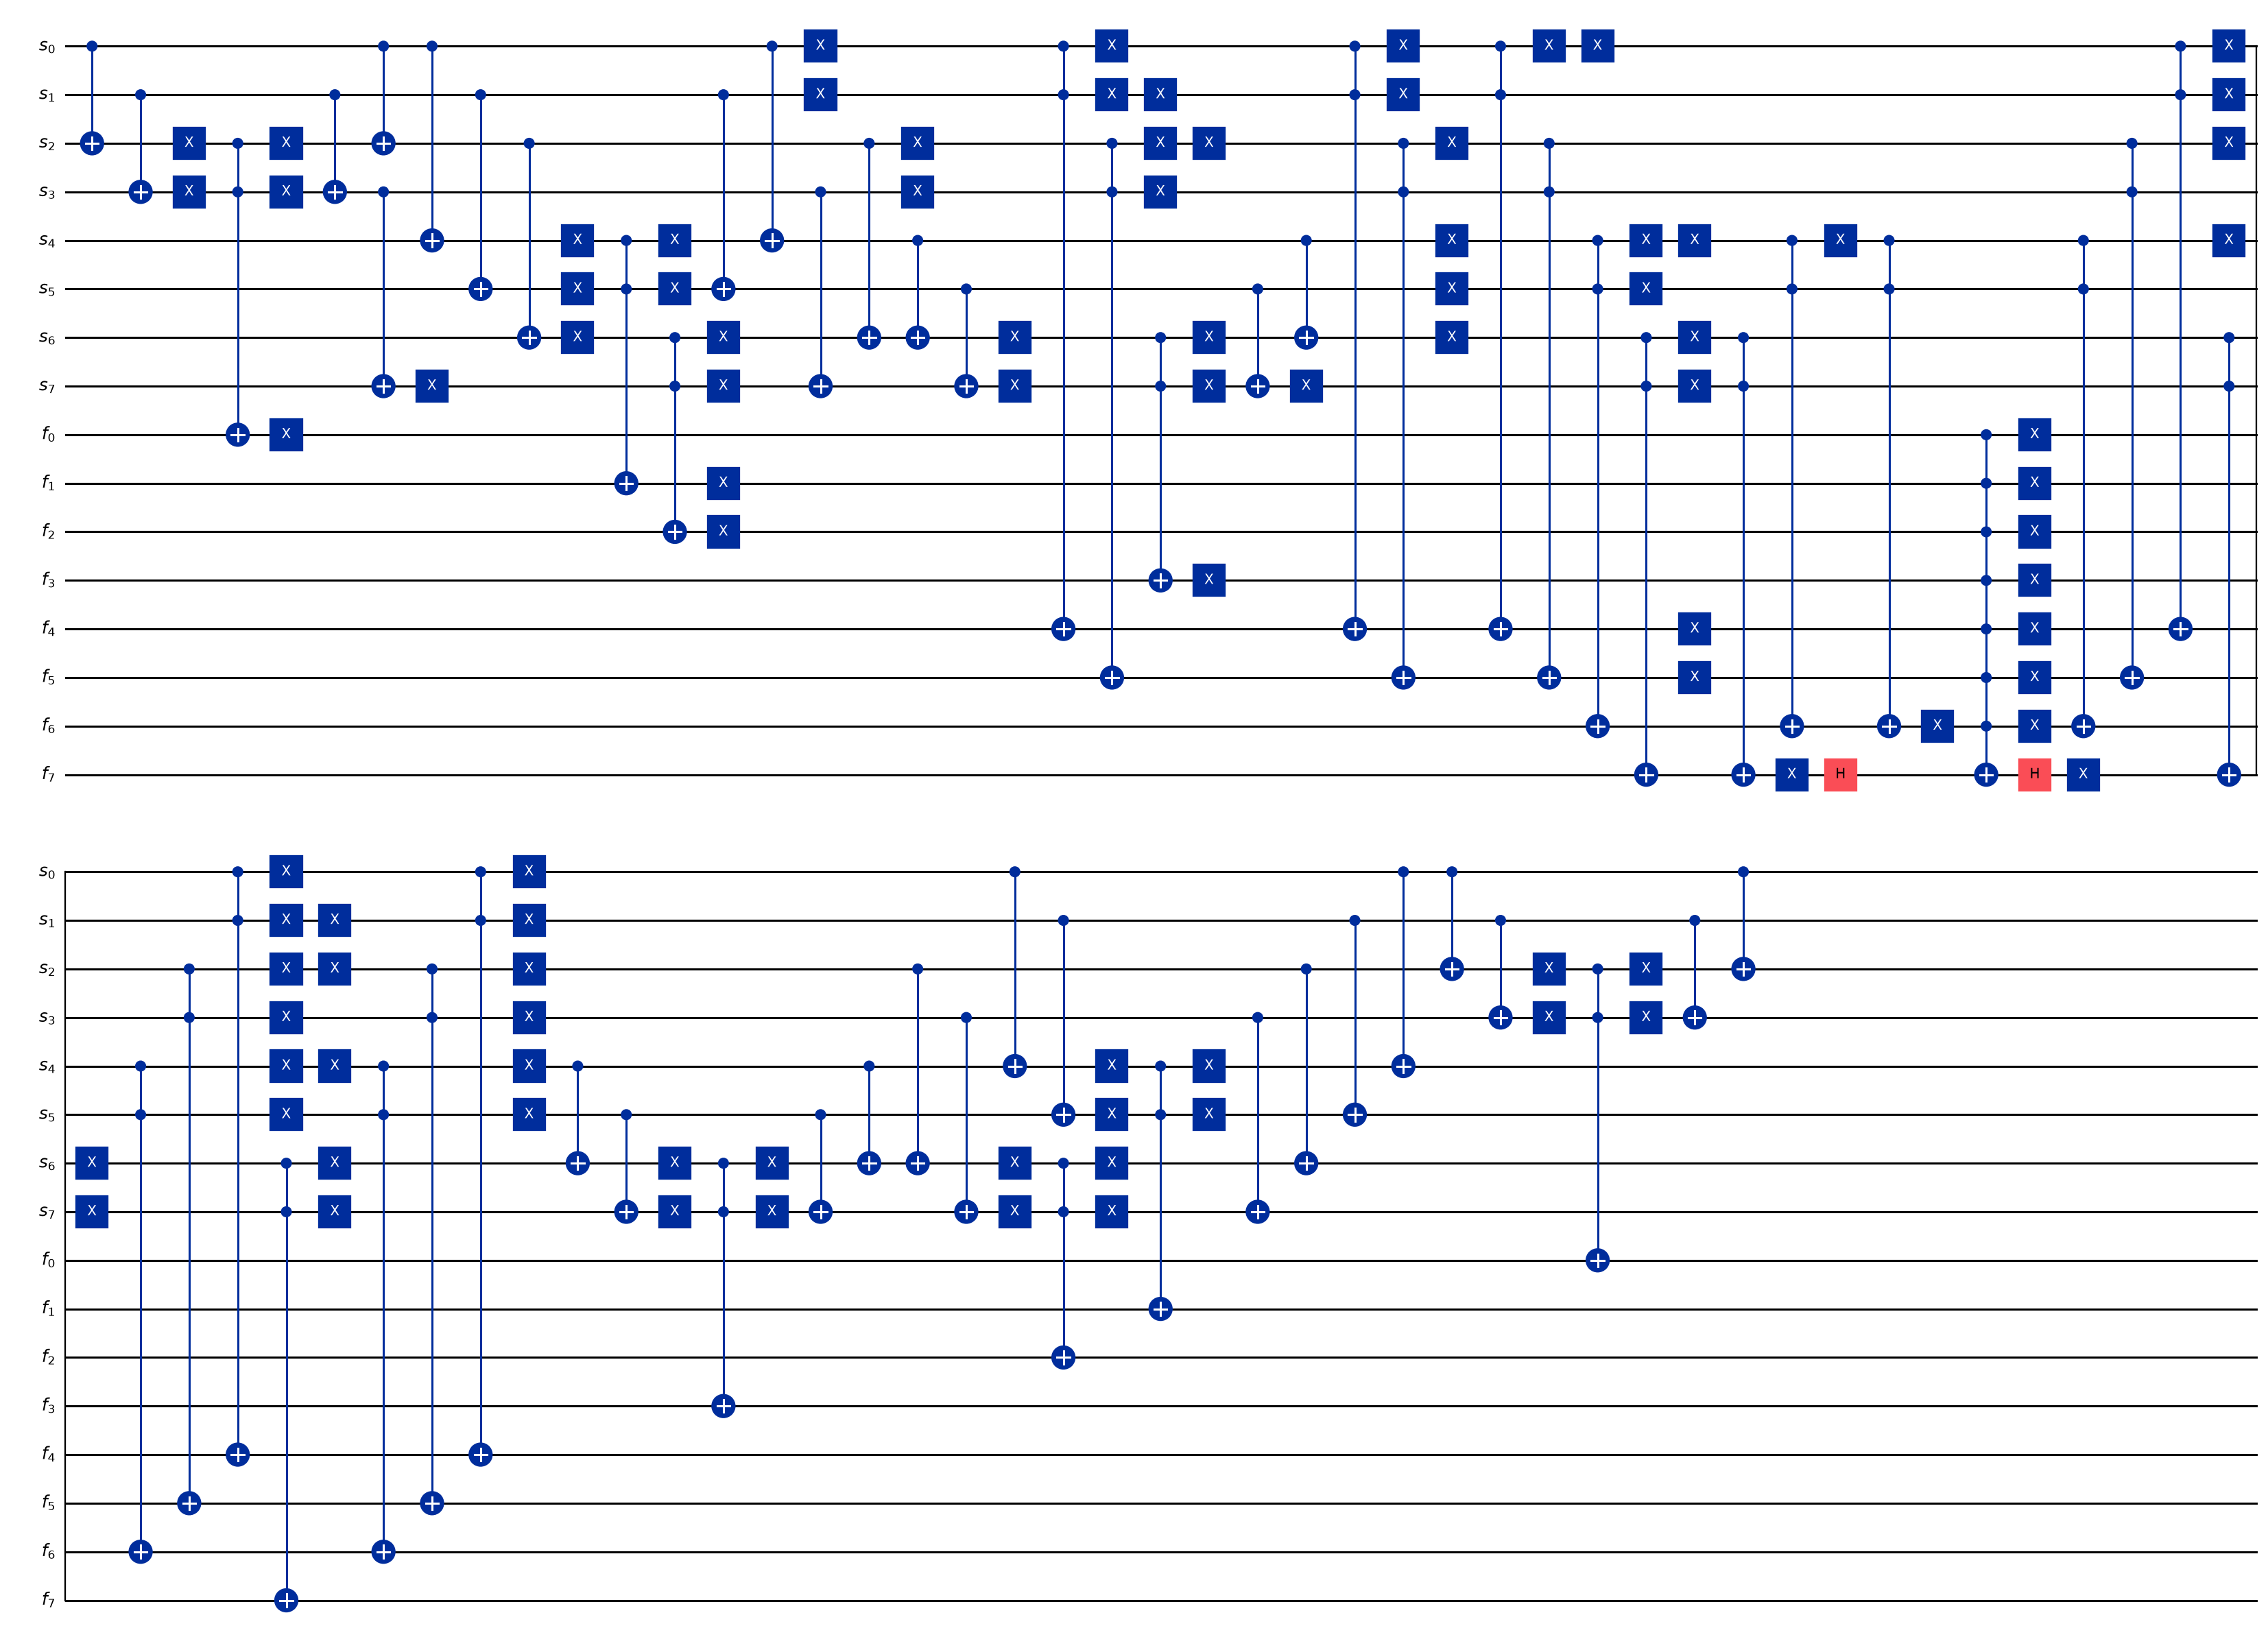

In [9]:
oracle = build_oracle(sp)
print(f"{oracle.num_qubits} qubits, {len(oracle.data)} operations")
oracle.draw("mpl", fold=45, style={"backgroundcolor": "#FFFFFF"})

**Test: the oracle flips the sign of exactly the valid fillings and leaves the flags clean.**

In [10]:
from qiskit.quantum_info import Statevector
mask = sp.solution_mask()
bad = 0
for x in range(sp.space):                              # every possible filling
    prep = QuantumCircuit(sp.n_qubits)
    for i in range(sp.n_search):
        if (x >> i) & 1: prep.x(i)
    before = Statevector(prep)
    overlap = np.vdot(before.data, before.evolve(oracle).data)   # +1 untouched, -1 marked
    if not np.isclose(overlap, -1.0 if mask[x] else 1.0): bad += 1
print(f"checked all {sp.space} fillings, wrong: {bad}")
print("valid fillings:", [pz.to_string(sp.to_grid(x)) for x in sp.solution_indices()])

checked all 256 fillings, wrong: 0
valid fillings: ['4132/3214/2341/1423']


## 6. The diffuser and the full Grover circuit
The **diffuser** reflects every amplitude about the average (`H`, `X`, multi-controlled `Z`, `X`, `H`): the marked state's amplitude grows each round.

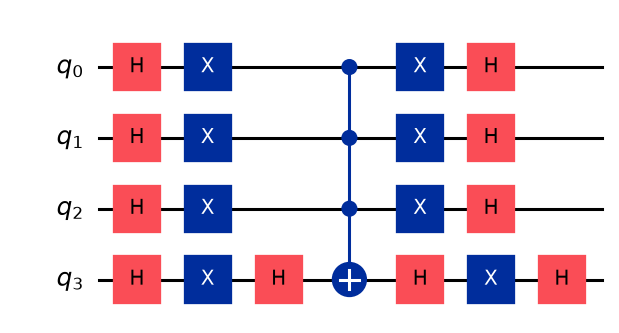

In [11]:
build_diffuser(4).draw("mpl", style={"backgroundcolor": "#FFFFFF"})

12 rounds. One round of the circuit (Oracle and Diffuser boxed):


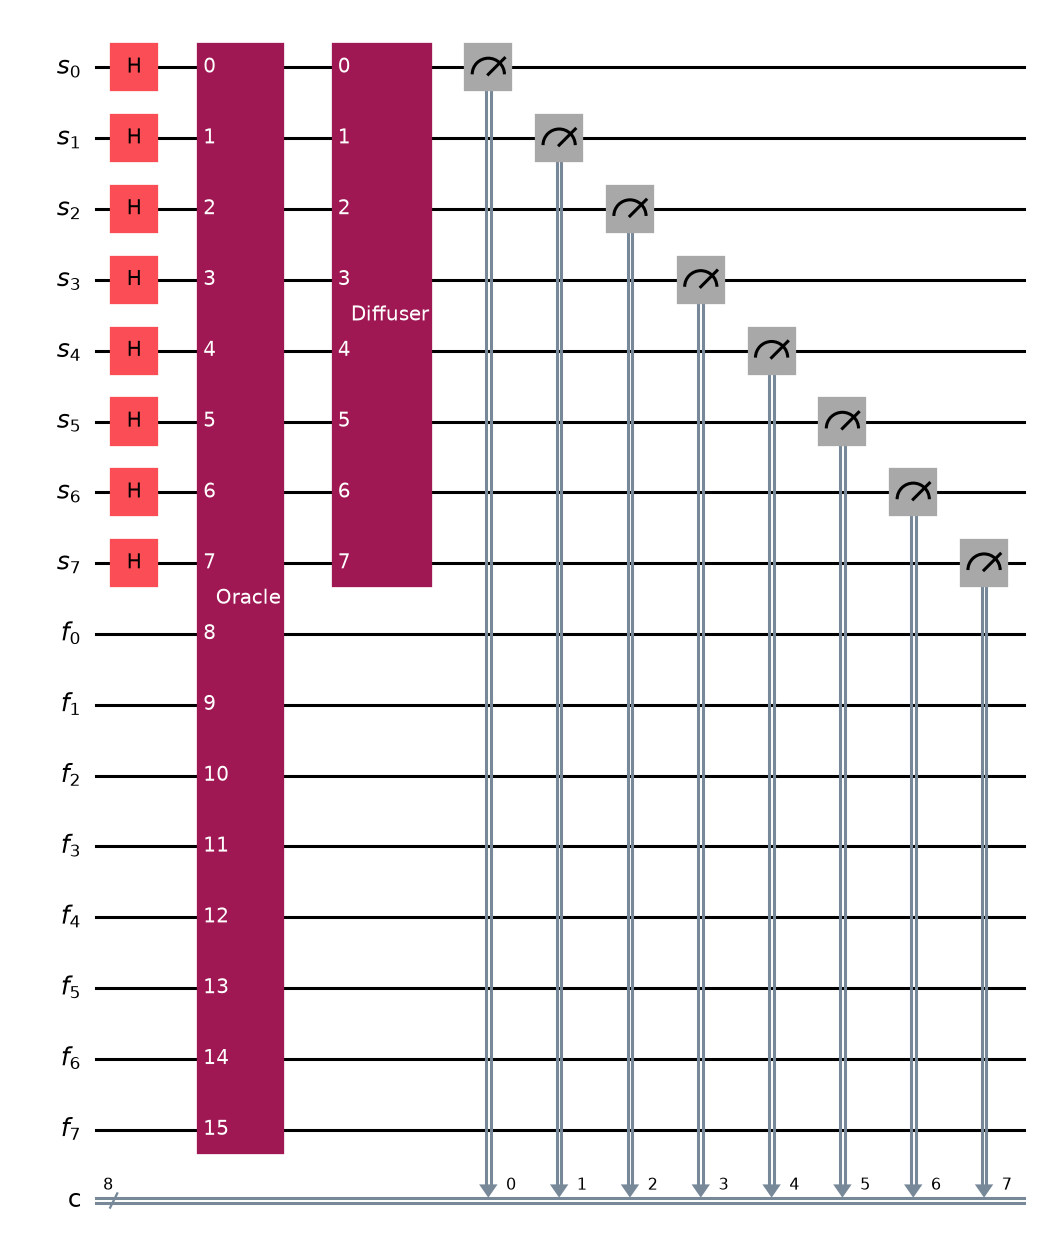

In [12]:
k = optimal_iterations(sp.space, sp.n_solutions)
print(f"{k} rounds. One round of the circuit (Oracle and Diffuser boxed):")
build_grover_circuit(sp, 1, boxed=True).draw("mpl", fold=-1, style={"backgroundcolor": "#FFFFFF"})

## 7. Running it on Qiskit Aer
`run_grover` builds the full circuit and runs it on Aer's state-vector simulator. The measured filling is checked against the rules.

backend=aer  rounds=12  qubits=16  time=1.1s
solved=True  measured success=100.0%  exact=99.995%


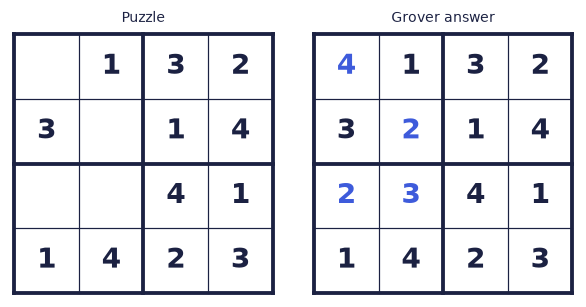

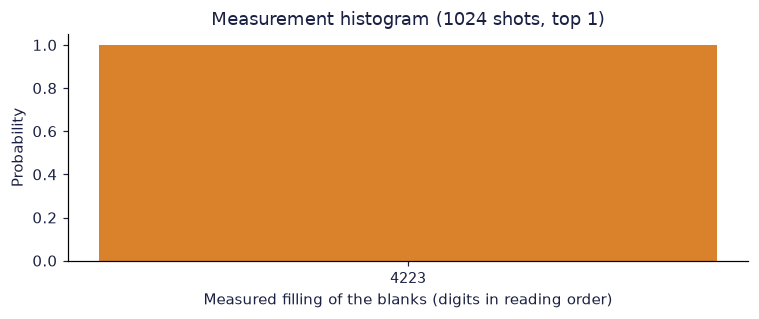

In [13]:
t = time.time()
g = run_grover(q.grid, shots=1024, seed=7, backend="aer")
print(f"backend={g.backend}  rounds={g.iterations}  qubits={g.problem.n_qubits}  time={time.time()-t:.1f}s")
print(f"solved={g.solved}  measured success={g.success_probability:.1%}  exact={g.exact_probability:.3%}")
fig, axes = plt.subplots(1, 2, figsize=(5.6, 2.8))
viz.draw_grid(q.grid, title="Puzzle", ax=axes[0])
viz.draw_grid(g.solution, q.grid, title="Grover answer", ax=axes[1])
plt.tight_layout(); plt.show()
viz.plot_histogram(g); plt.show()

With one solution among 256 fillings the answer takes about 100 % of the shots, so the histogram has a single bar. On a log scale you can see the other outcomes almost vanish:

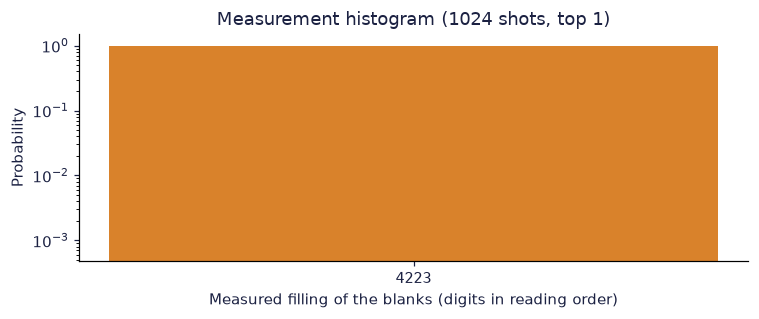

In [14]:
viz.plot_histogram(g, log=True); plt.show()

## 8. Checking the circuit against the maths
The app uses two backends. **aer** simulates the real gate-level circuit (all search + helper qubits). **fast** simulates only the search register with NumPy (oracle = sign flip on valid fillings, diffuser = inversion about the mean). If they agree *exactly*, the fast one is a faithful stand-in when the circuit is too big.

In [15]:
for kk in (0, 1, 3, 12):
    exact_circuit = statevector_probabilities(sp, kk)       # from the real circuit
    exact_numpy = simulate_fast(sp, kk)                      # from the maths
    print(f"k={kk:2d}  max |difference| = {np.abs(exact_circuit - exact_numpy).max():.2e}"
          f"   P(success) circuit={exact_circuit[mask].sum():.6f}  numpy={exact_numpy[mask].sum():.6f}"
          f"  formula={theoretical_success(sp.space, 1, kk):.6f}")

k= 0  max |difference| = 5.20e-18   P(success) circuit=0.003906  numpy=0.003906  formula=0.003906


k= 1  max |difference| = 1.67e-16   P(success) circuit=0.034791  numpy=0.034791  formula=0.034791


k= 3  max |difference| = 2.58e-15   P(success) circuit=0.179721  numpy=0.179721  formula=0.179721


k=12  max |difference| = 5.88e-14   P(success) circuit=0.999947  numpy=0.999947  formula=0.999947


## 9. How many rounds? Success probability and over-rotation
After *k* rounds, P(success) = sin²((2k+1)θ), where sin θ = √(M/N). It rises, peaks, then **falls again** — Grover keeps rotating the state and overshoots the answer.

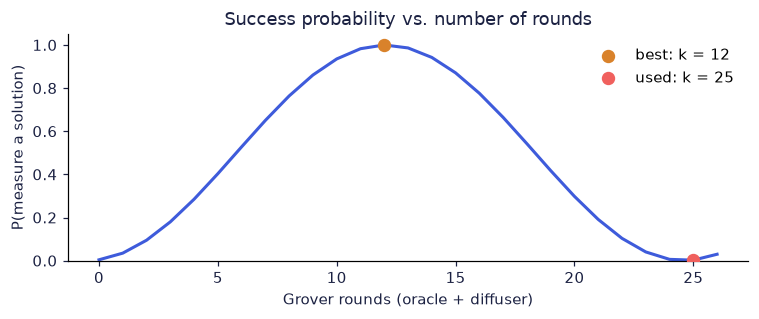

k=12: exact P(success)=99.995%
k=25 : exact P(success)=0.230%   <- too many rounds


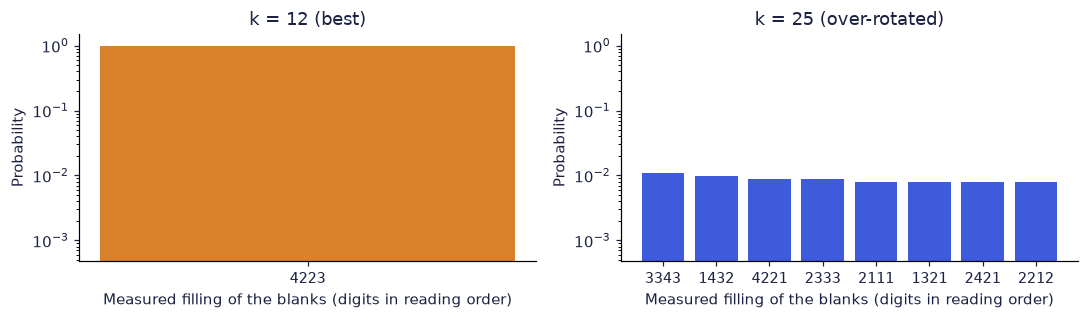

In [16]:
viz.plot_success_curve(sp, k_used=25); plt.show()
best = run_grover(q.grid, backend="fast", seed=1)
over = run_grover(q.grid, backend="fast", seed=1, iterations=25)
print(f"k={best.iterations}: exact P(success)={best.exact_probability:.3%}")
print(f"k=25 : exact P(success)={over.exact_probability:.3%}   <- too many rounds")
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
viz.plot_histogram(best, ax=axes[0], log=True); axes[0].set_title("k = 12 (best)")
viz.plot_histogram(over, ax=axes[1], log=True); axes[1].set_title("k = 25 (over-rotated)")
plt.tight_layout(); plt.show()

## 10. Medium and Hard
The circuit for Medium needs 23–27 qubits and 50 rounds; Hard needs 34–39 qubits and 201 rounds. On this machine one Medium run on the gate-level Aer simulator took **about 45 minutes** (2,704 s), and Hard does not fit in memory. So for these levels the app uses the NumPy backend, which section 8 showed gives identical probabilities.

In [17]:
rows = []
for level in pz.LEVELS:
    qq = pz.PRESETS[level][0]
    r = run_grover(qq.grid, shots=1024, seed=3)          # backend="auto"
    rows.append({"level": level, "backend": r.backend, "search qubits": r.problem.n_search,
                 "total qubits": r.problem.n_qubits, "fillings": r.problem.space, "rounds": r.iterations,
                 "exact P(success)": r.exact_probability, "measured": r.success_probability,
                 "solved": r.solved and r.solution == qq.solution})
pd.DataFrame(rows)

,level,backend,search qubits,total qubits,fillings,rounds,exact P(success),measured,solved
0,Easy,aer,8,15,256,12,1.0,1.0,True
1,Medium,fast,12,27,4096,50,1.0,1.0,True
2,Hard,fast,16,39,65536,201,1.0,1.0,True


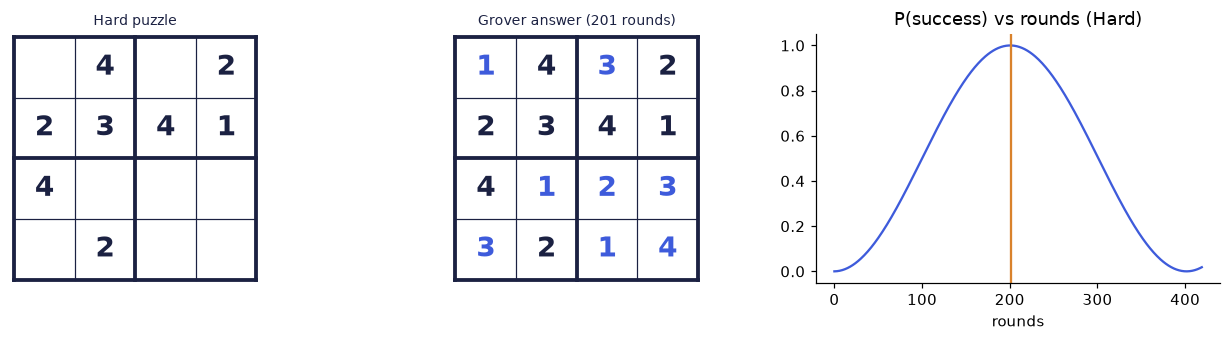

In [18]:
hard = pz.PRESETS["Hard"][0]
rh = run_grover(hard.grid, shots=1024, seed=3)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
viz.draw_grid(hard.grid, title="Hard puzzle", ax=axes[0])
viz.draw_grid(rh.solution, hard.grid, title=f"Grover answer ({rh.iterations} rounds)", ax=axes[1])
axes[2].plot(range(0, 420, 1), [theoretical_success(rh.problem.space, 1, k) for k in range(420)], color=viz.BLUE)
axes[2].axvline(rh.iterations, color=viz.ORANGE); axes[2].set_title("P(success) vs rounds (Hard)")
axes[2].set_xlabel("rounds")
plt.tight_layout(); plt.show()

## 11. Cost of the real circuit
Qiskit breaks `MCX`/`MCZ` into basic gates (`H`, `T`, `T†`, `S`, `X`, `Z`, `CX`). This is what a real quantum computer would have to run.

In [19]:
rows = []
for level in pz.LEVELS:
    qq = pz.PRESETS[level][0]
    sp_ = SearchProblem.from_grid(qq.grid)
    k_ = optimal_iterations(sp_.space, 1)
    s = circuit_stats(sp_, k_)
    rows.append({"level": level, "qubits": s.qubits, "rounds": k_, "depth / round": s.depth_per_round,
                 "total depth": s.total_depth, "CX gates / round": s.oracle_gates.get("cx", 0),
                 "total CX gates": s.total_cx})
pd.DataFrame(rows)

,level,qubits,rounds,depth / round,total depth,CX gates / round,total CX gates
0,Easy,15,12,325,3900,272,3264
1,Medium,27,50,649,32450,548,27400
2,Hard,39,201,945,189945,800,160800


Hard needs on the order of **10⁵ two-qubit gates**. Today's hardware has two-qubit error rates around 10⁻³, so the answer would be pure noise — this is why we simulate (section 13 shows the effect on a tiny example).

## 12. Classical vs Grover: the honest comparison
Same puzzle, same rules, two solvers. We compare **correctness**, **search effort** and **success probability**.

In [20]:
c = compare(pz.PRESETS["Easy"][0].grid, seed=1)
pd.DataFrame(c.rows())

,metric,Classical,Grover
0,Solved,True,True
1,Success probability,1.0,1.0
2,Search effort,12 tries,12 oracle queries
3,Search space,pruned by rules,256 fillings
4,Time (s),0.0,0.086


In [21]:
rows = benchmark(n_puzzles=8, backend="fast", seed=100)
df = pd.DataFrame(rows)
summary = df.groupby("level", sort=False).agg(
    blanks=("blanks", "first"), fillings=("fillings", "first"),
    classical_tries=("classical_tries", "mean"), grover_queries=("grover_queries", "first"),
    unstructured_avg=("brute_force_avg", "mean"), grover_success=("grover_success", "mean"),
    both_correct=("grover_correct", "all"))
summary

,blanks,fillings,classical_tries,grover_queries,unstructured_avg,grover_success,both_correct
level,,,,,,,
Easy,4,256,11.375,12,128.5,1.0,True
Medium,6,4096,17.375,50,2048.5,1.0,True
Hard,8,65536,22.500,201,32768.5,1.0,True


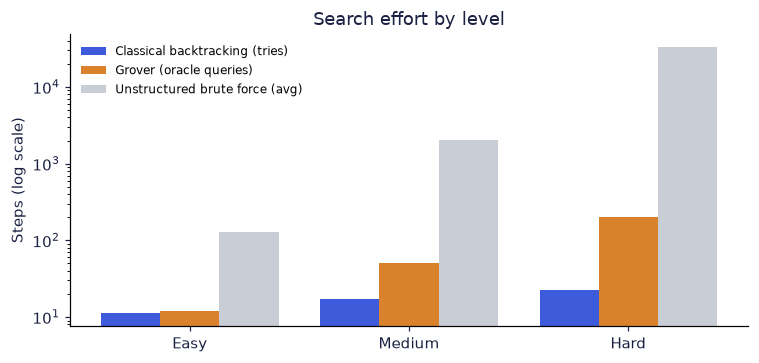

In [22]:
viz.plot_effort(rows); plt.show()

**Reading the result honestly.**
- Both solvers are **correct** on every puzzle.
- Backtracking needs only ~10–30 tries because it *uses the rules to cut branches*. Grover's oracle treats the puzzle as a black box that says "valid / not valid".
- Against an **unstructured** search (guess fillings until one is valid), Grover needs about √N queries instead of N/2: 12 vs ~128 on Easy, 201 vs ~32,768 on Hard. That quadratic speed-up is the real quantum result here.
- A fair headline: *on 4×4 Sudoku a smart classical solver wins; Grover shows the √N advantage for unstructured search, and the gap in favour of Grover grows with the size of the search space.*

## 13. What noise does to it
A real device makes errors. We run a **tiny** instance (2 blanks, 4 search qubits) with depolarising noise on every `CX` and see how the success probability decays. The Easy puzzle already has far more gates than this toy.

toy: 2 blanks, 4 search + 3 helper qubits, 16 fillings, 1 solution(s), 3 rounds
CX gates in the transpiled circuit: 336  depth: 386


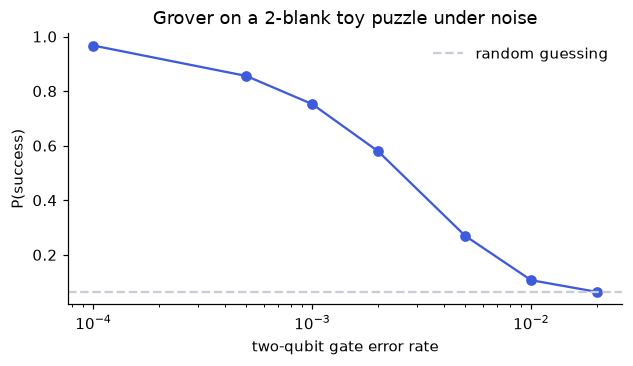

,CX error,P(success)
0,0.000e+00,0.967
1,5.000e-04,0.856
2,1.000e-03,0.752
3,2.000e-03,0.580
4,5.000e-03,0.270
5,1.000e-02,0.107
6,2.000e-02,0.064


In [23]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

toy_grid = pz.parse("1432/2341/4..3/3214")
toy = SearchProblem.from_grid(toy_grid)
k_toy = optimal_iterations(toy.space, toy.n_solutions)
print(f"toy: {toy.n_blanks} blanks, {toy.n_search} search + {toy.n_flags} helper qubits, "
      f"{toy.space} fillings, {toy.n_solutions} solution(s), {k_toy} rounds")

qc = build_grover_circuit(toy, k_toy, measure=True)
tq = transpile(qc, basis_gates=["cx", "u"], optimization_level=1, seed_transpiler=1)
print("CX gates in the transpiled circuit:", tq.count_ops().get("cx", 0), " depth:", tq.depth())

toy_mask = toy.solution_mask()
def success_with_noise(p, shots=2000):
    nm = NoiseModel()
    if p > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p, 2), ["cx"])
        nm.add_all_qubit_quantum_error(depolarizing_error(p / 10, 1), ["u"])
    counts = AerSimulator(noise_model=nm).run(tq, shots=shots, seed_simulator=5).result().get_counts()
    return sum(c for bits, c in counts.items() if toy_mask[int(bits, 2)]) / shots

ps = [0, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02]
ys = [success_with_noise(p) for p in ps]
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot([max(p, 1e-4) for p in ps], ys, "o-", color=viz.BLUE)
ax.axhline(1 / toy.space, color=viz.GREY, ls="--", label="random guessing")
ax.set_xscale("log"); ax.set_xlabel("two-qubit gate error rate"); ax.set_ylabel("P(success)")
ax.set_title("Grover on a 2-blank toy puzzle under noise"); ax.legend(frameon=False); plt.show()
pd.DataFrame({"CX error": ps, "P(success)": ys})

## 14. Summary
| | |
|---|---|
| **Classical** | Backtracking solves every 4×4 puzzle with ~10–30 tries (pruning alone solves most). Deterministic: success probability 100 %. |
| **Quantum** | Grover with 2 qubits per blank, one helper qubit per rule. Needs ≈ π/4·√N rounds: **12 / 50 / 201** for Easy / Medium / Hard. Success probability ≈ 99.99 %, and it drops again if you run too many rounds. |
| **Verified** | The oracle flips exactly the valid fillings; the circuit's probabilities equal the NumPy simulator's to 10⁻⁹. |
| **Limits** | Gate-level Aer is practical only for Easy (15–16 qubits); Medium took ~45 min; Hard does not fit. Real hardware would drown in noise (section 13). |
| **Takeaway** | The quantum advantage is **√N vs N** for unstructured search, not "Grover beats a good Sudoku solver". |

**Run the app:** `streamlit run app.py` (from the `quantum_sudoku` folder).